In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [ ]:

# === Load the CSV file ===
# If you have a file, replace this with pd.read_csv("your_file.csv")
csv_path = "exp_lr4.7e-3_step6_gamma0.808_epochs100_cls7_ch6_win1024_stride256_bs32_wd6.7e-5_A.csv"
df = pd.read_csv(csv_path)

In [3]:

# Convert 'validation' to boolean if needed
df['validation'] = df['validation'].astype(bool)

# === Split into training and validation sets ===
df_train = df[df['validation'] == False]
df_val = df[df['validation'] == True]

In [4]:

# === Pivot the data for plotting ===
# Create pivoted dataframes where rows are epochs and columns are metrics
train_pivot = df_train.pivot(index='epoch', columns='metric', values='values')
val_pivot = df_val.pivot(index='epoch', columns='metric', values='values')

In [5]:

# === Convert values to float for plotting ===
train_pivot = train_pivot.astype(float)
val_pivot = val_pivot.astype(float)

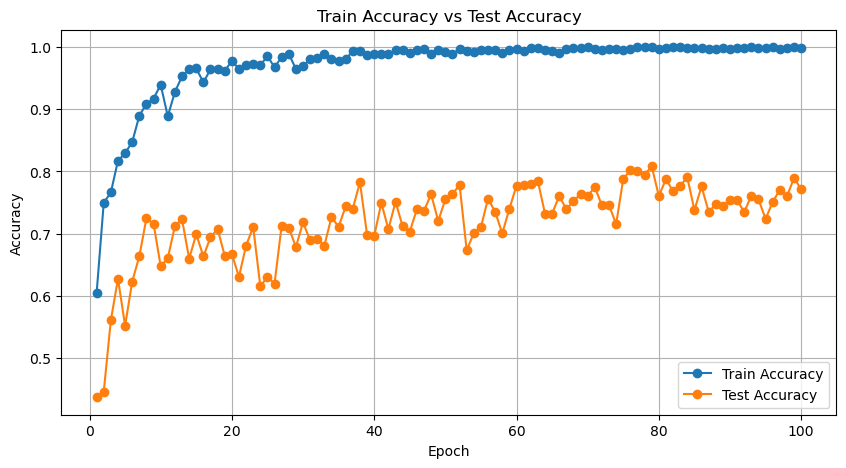

In [6]:

# === Plot Train Accuracy vs Test Accuracy ===
plt.figure(figsize=(10, 5))
plt.plot(train_pivot.index, train_pivot['metrics.TRAIN_ACC'], label='Train Accuracy', marker='o')
plt.plot(val_pivot.index, val_pivot['metrics.TEST_ACC'], label='Test Accuracy', marker='o')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Train Accuracy vs Test Accuracy')
plt.legend()
plt.grid(True)
plt.show()

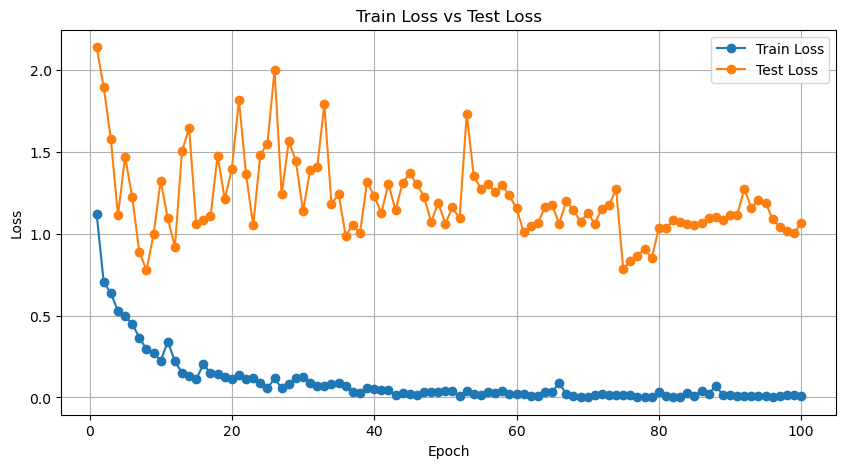

In [7]:

# === Plot Train Loss vs Test Loss ===
plt.figure(figsize=(10, 5))
plt.plot(train_pivot.index, train_pivot['metrics.LOSS'], label='Train Loss', marker='o')
plt.plot(val_pivot.index, val_pivot['metrics.LOSS'], label='Test Loss', marker='o')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Train Loss vs Test Loss')
plt.legend()
plt.grid(True)
plt.show()